# Reference paper: Reconstructing 6-hourly PM2.5 datasets from 1960 to 2020 in China


## Data Source

Due to access restrictions, obtaining the raw data from the original study 'Reconstructing 6-hourly $PM_{2.5}$ datasets from 1960 to 2020 in China' requires formal application to the relevant authorities. To ensure research efficiency, this study instead utilizes a high-quality alternative dataset sourced from Kaggle. [Beijing Multi-Site Air Quality Data on Kaggle](https://www.kaggle.com/datasets/aravindpcoder/beijing-multi-site-air-quality-data)

This dataset includes hourly air pollutants data from 12 nationally-controlled air-quality monitoring sites. The air-quality data are from the Beijing Municipal Environmental Monitoring Center. The meteorological data in each air-quality site are matched with the nearest weather station from the China Meteorological Administration. The time period is from March 1st, 2013 to February 28th, 2017. Missing data are denoted as `NA`.

Note that :

The dataset doesn't contain spatial information. I additionally introduced station-level geographic features, including longitude, latitude, and elevation.
I also added a new variable relative humidity (`RH`) as one of the important factors associated with PM2.5 concentration. $RH = 100 \cdot (E / E_s)$. RH can be calculated using Temperature and Dew Point within the range(0,100).
$$E_s = 6.112 \cdot \exp\left(\frac{17.67 \cdot TEMP}{TEMP + 243.5}\right)$$
$$E = 6.112 \cdot \exp\left(\frac{17.67 \cdot DEWP}{DEWP + 243.5}\right)$$






In [1]:
from pathlib import Path
import io

import sys
import subprocess
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler


In [2]:
sns.set_theme(style="whitegrid", context="talk")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

from google.colab import drive
drive.mount('/content/drive')

data_path = '/content/drive/MyDrive/PM2.5/Beijing Multisite air Quality data_with_geo.csv'
df = pd.read_csv(data_path)
df.head()


Mounted at /content/drive


,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station,lon,lat,elevation,RH
0,2013,3,1,0,4.00,4.00,4.00,7.00,300.00,77.00,-0.70,"1,023.00",-18.80,0.00,NNW,4.40,Aotizhongxin,116.40,39.98,46.00,23.99
1,2013,3,1,1,8.00,8.00,4.00,7.00,300.00,77.00,-1.10,"1,023.20",-18.20,0.00,N,4.70,Aotizhongxin,116.40,39.98,46.00,26.00
2,2013,3,1,2,7.00,7.00,5.00,10.00,300.00,73.00,-1.10,"1,023.50",-18.20,0.00,NNW,5.60,Aotizhongxin,116.40,39.98,46.00,26.00
3,2013,3,1,3,6.00,6.00,11.00,11.00,300.00,72.00,-1.40,"1,024.50",-19.40,0.00,NW,3.10,Aotizhongxin,116.40,39.98,46.00,23.99
4,2013,3,1,4,3.00,3.00,12.00,12.00,300.00,72.00,-2.00,"1,025.20",-19.50,0.00,N,2.00,Aotizhongxin,116.40,39.98,46.00,24.86


### Variable Reference

| Variable | Full Name | Unit |
|---|---|---|
| `PM2.5` | Fine Particulate Matter | `ug/m3` |
| `PM10` | Particulate Matter <= 10 um | `ug/m3` |
| `SO2` | Sulfur Dioxide | `ug/m3` |
| `NO2` | Nitrogen Dioxide | `ug/m3` |
| `CO` | Carbon Monoxide | `ug/m3` |
| `O3` | Ozone | `ug/m3` |
| `TEMP` | Air Temperature | `degC` |
| `PRES` | Atmospheric Pressure | `hPa` |
| `DEWP` | Dew Point Temperature | `degC` |
| `RAIN` | Precipitation / Rainfall | `mm` |
| `wd` | Wind Direction | categorical |
| `WSPM` | Wind Speed | `m/s` |
| `station` | Monitoring Station Name | categorical |
| `lon` | Longitude | decimal degrees |
| `lat` | Latitude | decimal degrees |
| `elevation` | Elevation above Sea Level | `m` |
| `RH` | Relative Humidity | `%` |

## 1. Data Integrity Check

In [3]:

info_buffer = io.StringIO()
df.info(buf=info_buffer)
print(info_buffer.getvalue())

numerical_columns = df.select_dtypes(include="number").columns.tolist()
categorical_columns = df.select_dtypes(exclude="number").columns.tolist()

print("Numerical columns:", numerical_columns)
print("Categorical columns:", categorical_columns)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 420768 entries, 0 to 420767
Data columns (total 21 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   year       420768 non-null  int64  
 1   month      420768 non-null  int64  
 2   day        420768 non-null  int64  
 3   hour       420768 non-null  int64  
 4   PM2.5      412029 non-null  float64
 5   PM10       414319 non-null  float64
 6   SO2        411747 non-null  float64
 7   NO2        408652 non-null  float64
 8   CO         400067 non-null  float64
 9   O3         407491 non-null  float64
 10  TEMP       420370 non-null  float64
 11  PRES       420375 non-null  float64
 12  DEWP       420365 non-null  float64
 13  RAIN       420378 non-null  float64
 14  wd         418946 non-null  object 
 15  WSPM       420450 non-null  float64
 16  station    420768 non-null  object 
 17  lon        420768 non-null  float64
 18  lat        420768 non-null  float64
 19  elevation  420768 non-n

Below the table shows

## 2. Missing Value Analysis

In [4]:
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
}).sort_values(["missing_count", "missing_pct"], ascending=False)

display(missing_summary)

focus_columns = ["SO2", "NO2", "CO", "O3", "TEMP", "PRES", "DEWP", "RAIN", "wd", "WSPM"]
focus_missing = missing_summary.loc[focus_columns].sort_values("missing_pct", ascending=False)

significant_gaps = missing_summary[missing_summary["missing_pct"] > 5]
print("Columns with more than 5% missing values:")
display(significant_gaps if not significant_gaps.empty else pd.DataFrame(columns=missing_summary.columns))

,missing_count,missing_pct
CO,20701,4.92
O3,13277,3.16
NO2,12116,2.88
SO2,9021,2.14
PM2.5,8739,2.08
PM10,6449,1.53
wd,1822,0.43
DEWP,403,0.10
RH,403,0.10
TEMP,398,0.09


Columns with more than 5% missing values:


,missing_count,missing_pct


Comments:

The dataset exhibits high overall quality, with no single feature exceeding a 5% missingness threshold.

Approximately 2.08% of the records lack $PM_{2.5}$ observations. To maintain the integrity of the ground-truth labels, these rows will be removed from the dataset.

$CO, O_3, NO_2, SO_2$ show the highest missing rates (ranging from 2.1% to 4.9%).We Use Median Imputation (by station) to fill these gaps without being skewed by outliers.

Weather variables ($TEMP, PRES, DEWP, RAIN, WSPM$) are exceptionally complete, with missing rates below 0.1%. Given that atmospheric conditions change gradually over time, we utilize Linear Interpolation.

## 3. Statistical Summary

In [5]:
summary_stats = df[["PM2.5", "RH","SO2","NO2","CO","O3","PRES","DEWP"]].describe().T
display(summary_stats)

,count,mean,std,min,25%,50%,75%,max
PM2.5,"412,029.00",79.79,80.82,2.00,20.00,55.00,111.00,999.00
RH,"420,365.00",53.23,25.37,1.69,30.91,52.09,74.93,100.00
SO2,"411,747.00",15.83,21.65,0.29,3.00,7.00,20.00,500.00
NO2,"408,652.00",50.64,35.13,1.03,23.00,43.00,71.00,290.00
CO,"400,067.00","1,230.77","1,160.18",100.00,500.00,900.00,"1,500.00","10,000.00"
O3,"407,491.00",57.37,56.66,0.21,11.00,45.00,82.00,"1,071.00"
PRES,"420,375.00","1,010.75",10.47,982.40,"1,002.30","1,010.40","1,019.00","1,042.80"
DEWP,"420,365.00",2.49,13.79,-43.40,-8.90,3.10,15.10,29.10


The air quality concentration data (PM2.5, SO2, CO, and O3) exhibit significant right-skewed distributions. Notably, the maximum values for PM2.5 (999 $\mu g/m^3$) and O3 (1,071 $\mu g/m^3$) are substantially higher than their respective 75th percentiles, suggesting the presence of extreme pollution events or potential sensor anomalies. I then conduct an outlier analysis.

In [6]:
variables = ["PM2.5", "RH", "SO2", "NO2", "CO", "O3", "PRES", "DEWP"]

outlier_summary = []

for col in variables:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    mask = (df[col] < lower) | (df[col] > upper)

    outlier_summary.append({
        "variable": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "lower_bound": lower,
        "upper_bound": upper,
        "outlier_count": mask.sum(),
        "outlier_pct": round(mask.mean() * 100, 2)
    })

outlier_summary = pd.DataFrame(outlier_summary)
display(outlier_summary)


,variable,Q1,Q3,IQR,lower_bound,upper_bound,outlier_count,outlier_pct
0,PM2.5,20.00,111.00,91.00,-116.50,247.50,19142,4.55
1,RH,30.91,74.93,44.03,-35.13,140.97,0,0.00
2,SO2,3.00,20.00,17.00,-22.50,45.50,35566,8.45
3,NO2,23.00,71.00,48.00,-49.00,143.00,7021,1.67
4,CO,500.00,"1,500.00","1,000.00","-1,000.00","3,000.00",28054,6.67
5,O3,11.00,82.00,71.00,-95.50,188.50,16599,3.94
6,PRES,"1,002.30","1,019.00",16.70,977.25,"1,044.05",0,0.00
7,DEWP,-8.90,15.10,24.00,-44.90,51.10,0,0.00


Meteorological features (RH, PRES, DEWP) show zero outliers, indicating highly stable and consistent observations. All air pollutants exhibit significant outlier percentages, particularly SO2 (8.45%) and CO (6.67%). These outliers are likely not 'errors' but represent authentic extreme pollution events or heavy episodic emissions.

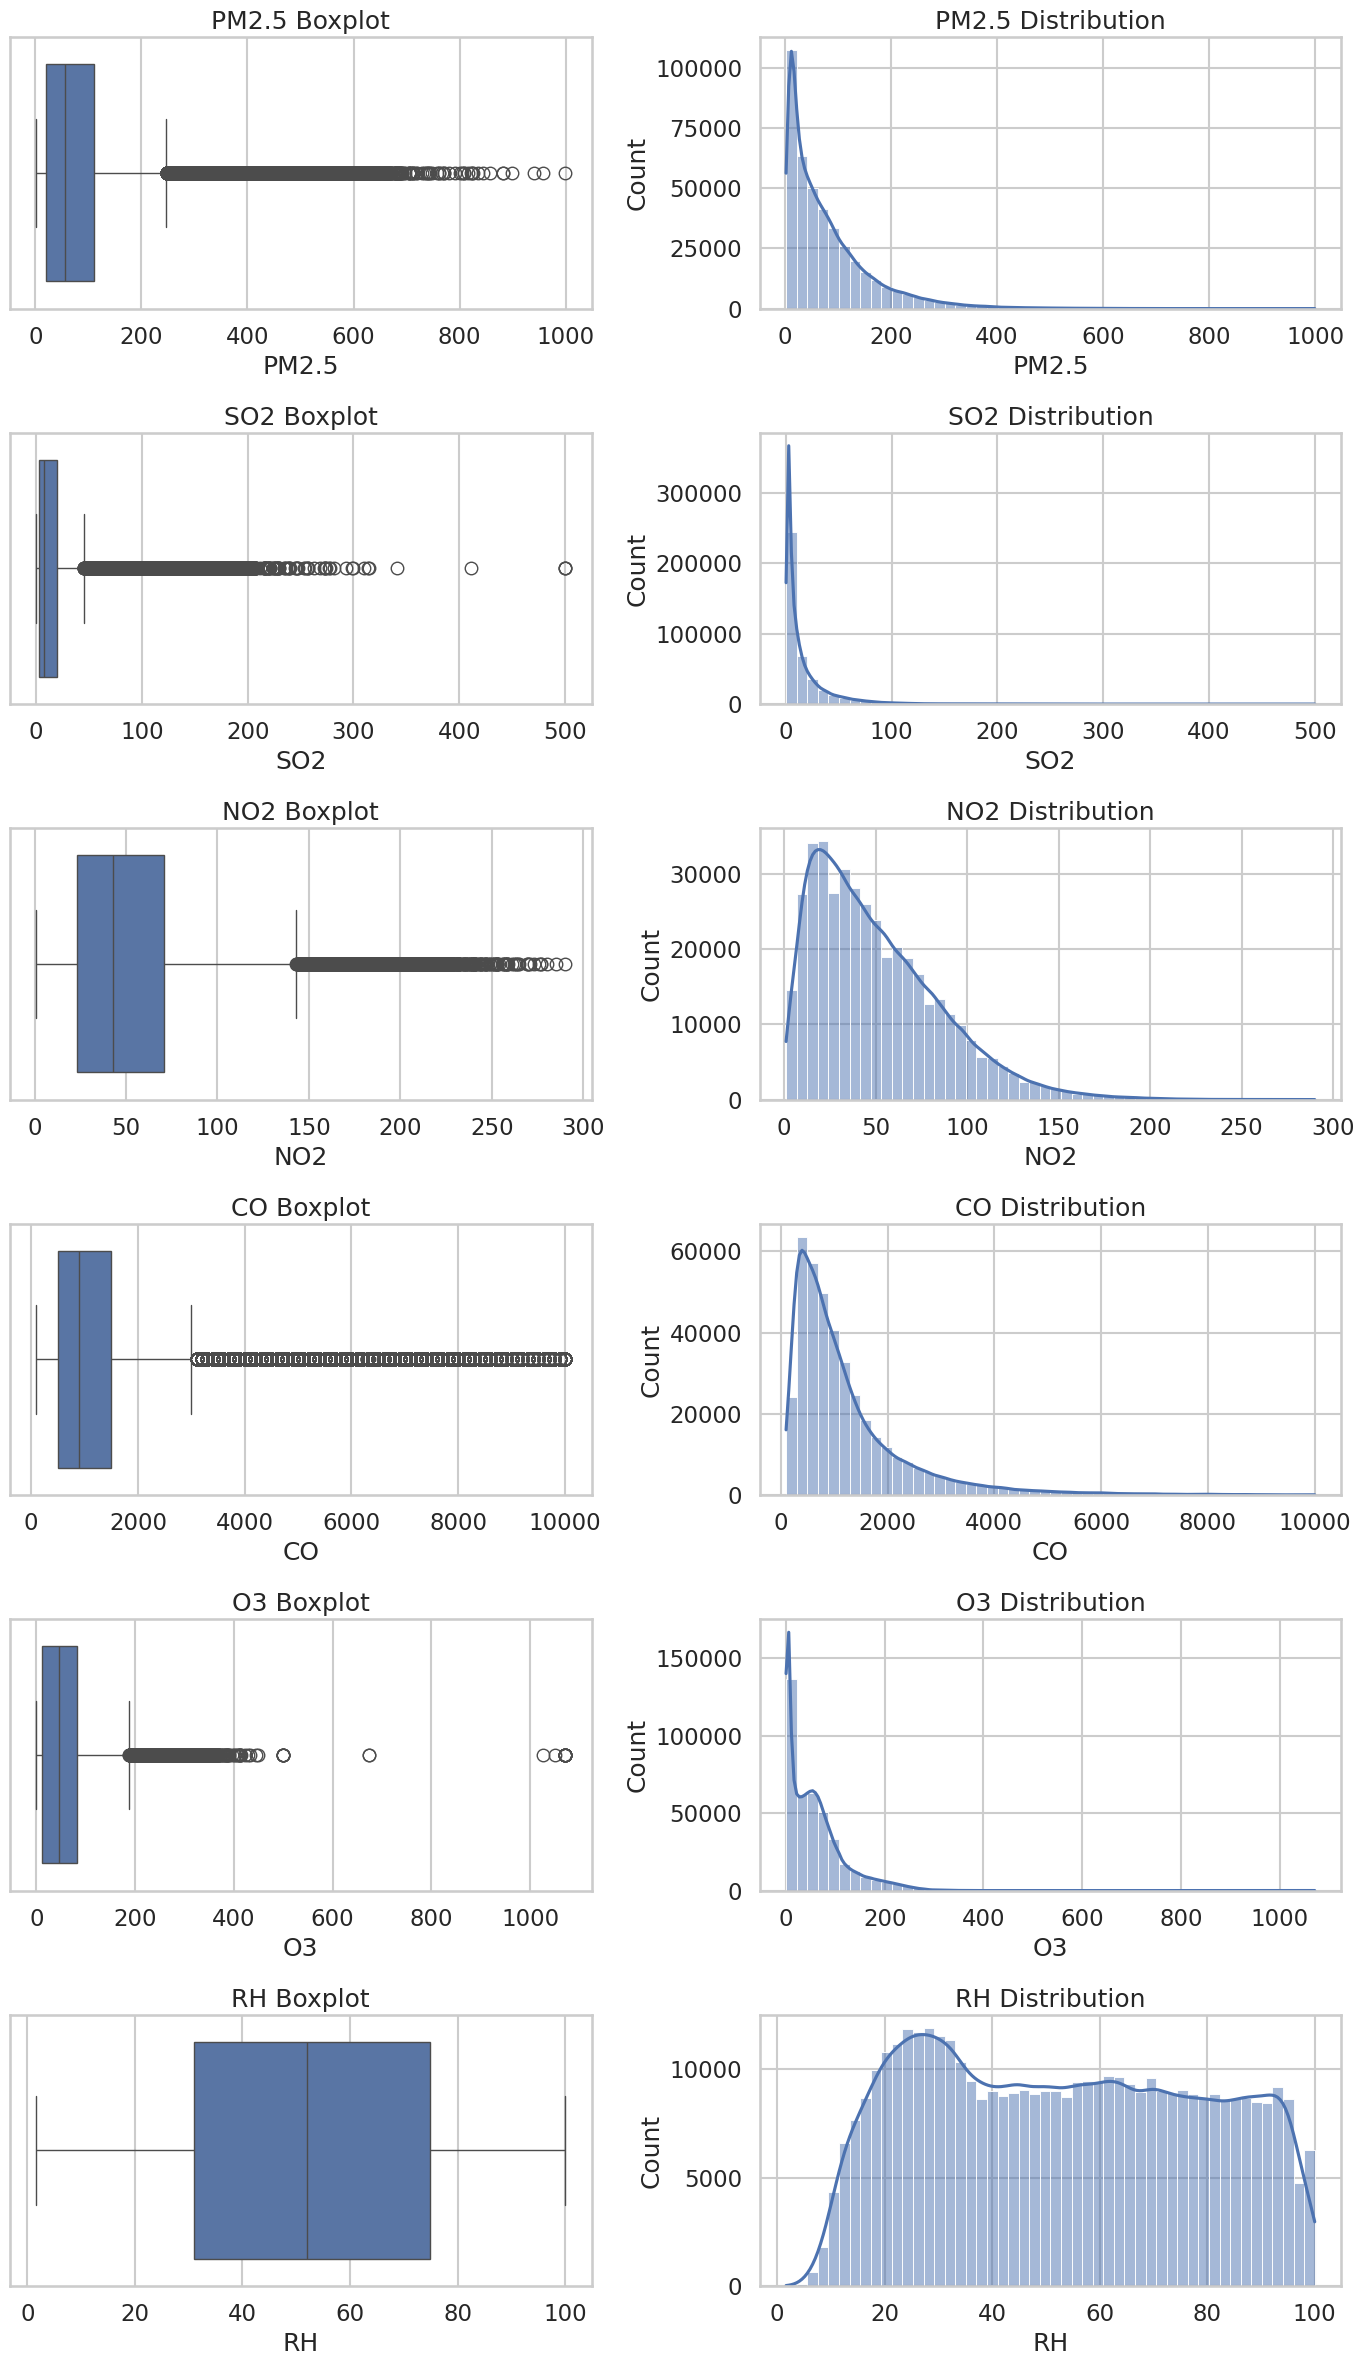

In [7]:

variables = ["PM2.5", "SO2", "NO2", "CO", "O3", "RH"]

fig, axes = plt.subplots(len(variables), 2, figsize=(14, 4 * len(variables)))

for i, col in enumerate(variables):
    sns.boxplot(x=df[col], ax=axes[i, 0])
    axes[i, 0].set_title(f"{col} Boxplot")

    sns.histplot(df[col], bins=50, kde=True, ax=axes[i, 1])
    axes[i, 1].set_title(f"{col} Distribution")

plt.tight_layout()
plt.show()


Visualization analysis furthur confirms that the 'outliers' are likely indicative of extreme pollution events rather than data errors. Specifically, the synchronous right-skewed tails across PM2.5, SO2, and CO suggest episodic, multi-pollutant accumulation typical of severe haze periods. The high continuity of observations in the PM2.5 tail further supports the authenticity of these extreme values. Therefore, these data points should be retained as valuable representations of peak pollution scenarios. In this case, data normalization (such as log-transformation) would be necessary for stable model convergence.

## 4. Correlation Analysis

,PM2.5
PM2.5,1.00
PM10,0.88
CO,0.79
NO2,0.67
SO2,0.48
RH,0.38
DEWP,0.11
PRES,0.02
hour,0.01
month,0.01


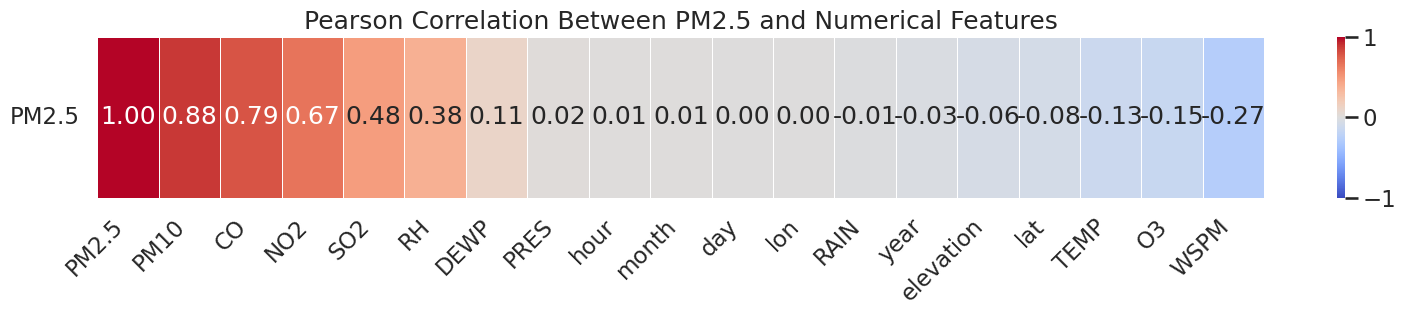

In [8]:
numeric_df = df.select_dtypes(include="number")
corr_matrix = numeric_df.corr(method="pearson")
pm25_corr = corr_matrix[["PM2.5"]].sort_values("PM2.5", ascending=False)

display(pm25_corr)

plt.figure(figsize=(16, 3.5))
sns.heatmap(
    pm25_corr.T,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
)
plt.title("Pearson Correlation Between PM2.5 and Numerical Features")
plt.yticks(rotation=0)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

There is a strong positive correlation with other pollutants, specifically $PM_{10}$ (0.88) and CO (0.79), indicating that $PM_{2.5}$ spikes are part of multi-pollutant events. To prevent data leakage and ensure a robust predictive model, $PM_{10}$ should be removed from the feature set.

Regarding meteorological factors, Relative Humidity (RH) shows a positive correlation (0.40), suggesting that moisture facilitates secondary particle formation.

In contrast, Wind Speed (WSPM) and Temperature (TEMP) exhibit negative correlations due to their roles in pollutant dispersion.


## 5. Temporal Trend Visualization

,datetime,avg_PM2.5
0,2013-03-01,104.89
1,2013-04-01,62.14
2,2013-05-01,81.85
3,2013-06-01,102.44
4,2013-07-01,67.91


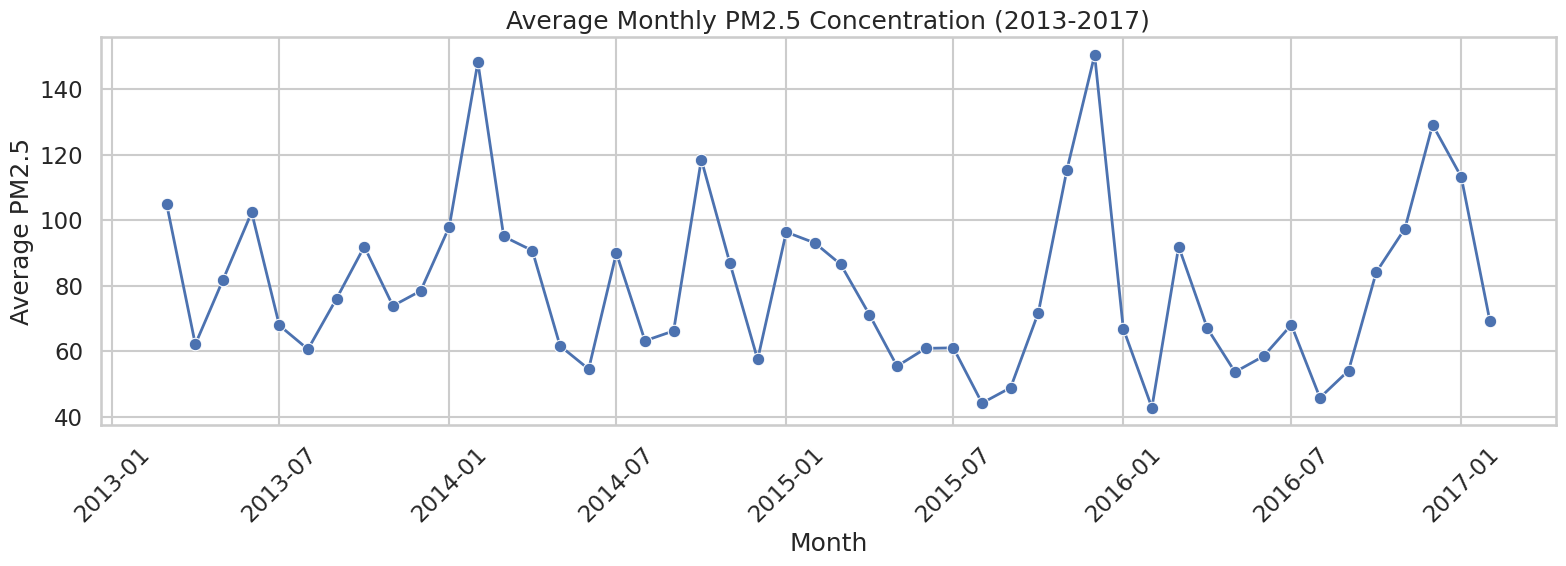

In [9]:

df["datetime"] = pd.to_datetime(df[["year", "month", "day", "hour"]])
monthly_pm25 = (
    df.set_index("datetime")["PM2.5"]
    .resample("MS")
    .mean()
    .reset_index(name="avg_PM2.5")
)

display(monthly_pm25.head())

plt.figure(figsize=(16, 6))
sns.lineplot(data=monthly_pm25, x="datetime", y="avg_PM2.5", marker="o", linewidth=2)
plt.title("Average Monthly PM2.5 Concentration (2013-2017)")
plt.xlabel("Month")
plt.ylabel("Average PM2.5")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Looking at the monthly trends from 2013 to 2017, the seasonal cycle is impossible to miss. $PM_{2.5}$ levels regularly spike every winter, specifically around January and February, which makes sense given the increase in coal heating and the stagnant air common in those months. On the flip side, summers stay relatively clean. While we see some crazy individual spikes in the data, the overall baseline seems to be dipping slightly over the years. This clear seasonality is why we can't just treat 'month' as a simple linear number in our model; we need to account for its cyclical nature.

## 6. Spatial Distribution Check

,station,PM2.5
3,Dongsi,86.19
11,Wanshouxigong,85.02
7,Nongzhanguan,84.84
5,Gucheng,83.85
10,Wanliu,83.37
4,Guanyuan,82.93
0,Aotizhongxin,82.77
9,Tiantan,82.16
8,Shunyi,79.49
1,Changping,71.10


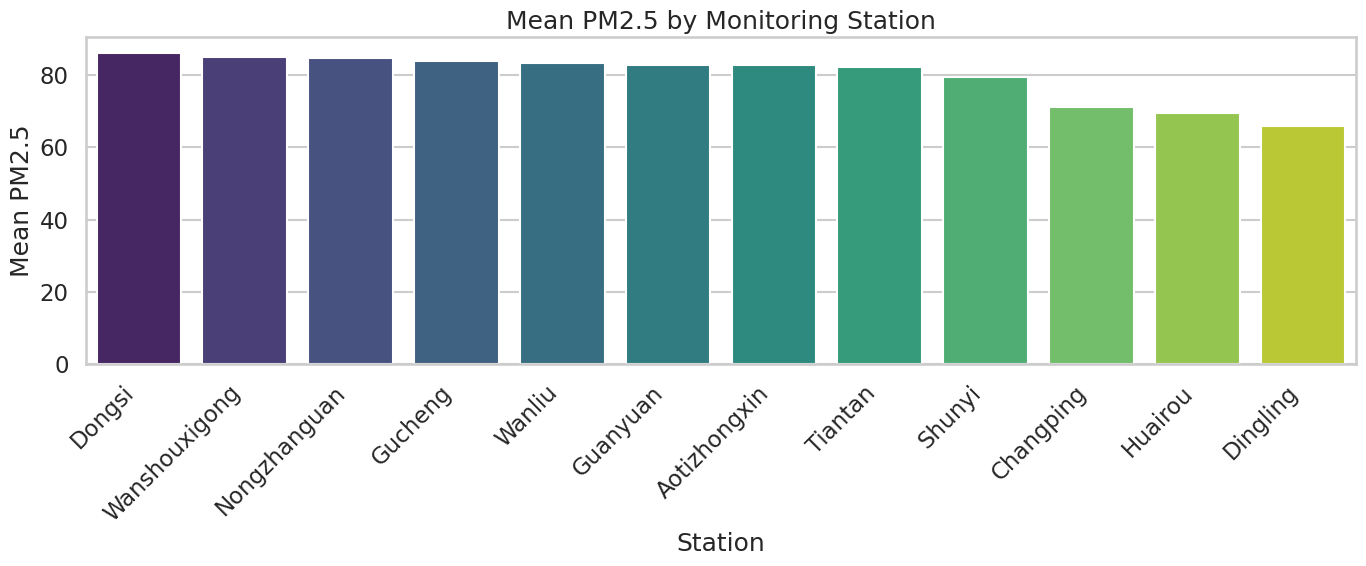

In [10]:
station_pm25 = (
    df.groupby("station", as_index=False)["PM2.5"]
    .mean()
    .sort_values("PM2.5", ascending=False)
)

display(station_pm25)

plt.figure(figsize=(14, 6))
sns.barplot(data=station_pm25, x="station", y="PM2.5", hue="station", dodge=False, legend=False, palette="viridis")
plt.title("Mean PM2.5 by Monitoring Station")
plt.xlabel("Station")
plt.ylabel("Mean PM2.5")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

The bar chart shows a clear gap in $PM_{2.5}$ levels between urban and suburban stations. Stations located in the city center, like Dongsi and Wanshouxigong, record the highest averages, likely due to heavy traffic and high population density. On the other hand, northern suburban sites like Dingling and Huairou stay significantly cleaner, which makes sense given their higher elevation and distance from major emission sources. For our model, this means we can't treat all stations the same; the location itself is a major factor in predicting air quality.

## Data Preprocessing

This section prepares the dataset for modeling. The main steps are:

1. Remove rows where `PM2.5` is missing and drop `PM10` to avoid leakage.
2. Impute gaseous pollutants by station-level median.
3. Interpolate meteorological variables linearly within each station.
4. Recompute `RH` from `TEMP` and `DEWP` after meteorological imputation.
5. Forward-fill missing wind direction values within each station.
6. Convert wind direction to degrees and apply cyclical encoding.
7. Apply cyclical encoding to `hour` and `month`.
8. One-hot encode `station`.
9. Apply `log(x + 1)` to `PM2.5`, `SO2`, `CO`, `NO2`, and `O3`. `RH` is not log-transformed.
10. Standardize the final feature matrix with Z-score scaling, including `RH`.

In [11]:

pollutant_cols = ["CO", "O3", "NO2", "SO2"]
meteorological_cols = ["TEMP", "PRES", "DEWP", "RAIN", "WSPM"]
log_transform_cols = ["PM2.5", "SO2", "CO", "NO2", "O3"]

preprocessed_df = df.copy().sort_values(["station", "year", "month", "day", "hour"]).reset_index(drop=True)
preprocessed_df = preprocessed_df.drop(columns=["datetime"], errors="ignore")
preprocessed_df["time_index"] = pd.to_datetime(preprocessed_df[["year", "month", "day", "hour"]])




In [12]:
# 1. Target cleaning and leakage prevention
preprocessed_df = preprocessed_df.dropna(subset=["PM2.5"]).copy()
preprocessed_df = preprocessed_df.drop(columns=["PM10"])

# 2. Station-wise median imputation for gaseous pollutants
for col in pollutant_cols:
    station_median = preprocessed_df.groupby("station")[col].transform("median")
    preprocessed_df[col] = preprocessed_df[col].fillna(station_median)
    preprocessed_df[col] = preprocessed_df[col].fillna(preprocessed_df[col].median())

# 3. Linear interpolation for meteorological variables within each station
for col in meteorological_cols:
    preprocessed_df[col] = preprocessed_df.groupby("station")[col].transform(
        lambda s: s.interpolate(method="linear", limit_direction="both")
    )

# Recompute RH after TEMP/DEWP interpolation to keep the derived feature consistent
es = 6.112 * np.exp((17.67 * preprocessed_df["TEMP"]) / (preprocessed_df["TEMP"] + 243.5))
e = 6.112 * np.exp((17.67 * preprocessed_df["DEWP"]) / (preprocessed_df["DEWP"] + 243.5))
preprocessed_df["RH"] = (100 * e / es).clip(0, 100)


In [13]:

# 4. Forward fill wind direction within each station


preprocessed_df["wd"] = preprocessed_df.groupby("station")["wd"].transform(lambda s: s.ffill())

# 5. Wind direction transformation and cyclical encoding
wind_direction_map = {
    "N": 0.0,
    "NNE": 22.5,
    "NE": 45.0,
    "ENE": 67.5,
    "E": 90.0,
    "ESE": 112.5,
    "SE": 135.0,
    "SSE": 157.5,
    "S": 180.0,
    "SSW": 202.5,
    "SW": 225.0,
    "WSW": 247.5,
    "W": 270.0,
    "WNW": 292.5,
    "NW": 315.0,
    "NNW": 337.5,
}
preprocessed_df["wd_degree"] = preprocessed_df["wd"].map(wind_direction_map)
preprocessed_df["wd_sin"] = np.sin(2 * np.pi * preprocessed_df["wd_degree"] / 360)
preprocessed_df["wd_cos"] = np.cos(2 * np.pi * preprocessed_df["wd_degree"] / 360)
preprocessed_df = preprocessed_df.drop(columns=["wd", "wd_degree"])

# 6. Cyclical encoding for hour and month
preprocessed_df["hour_sin"] = np.sin(2 * np.pi * preprocessed_df["hour"] / 24)
preprocessed_df["hour_cos"] = np.cos(2 * np.pi * preprocessed_df["hour"] / 24)
preprocessed_df["month_sin"] = np.sin(2 * np.pi * preprocessed_df["month"] / 12)
preprocessed_df["month_cos"] = np.cos(2 * np.pi * preprocessed_df["month"] / 12)
preprocessed_df = preprocessed_df.drop(columns=["year", "month", "day", "hour"])

# 7. One-hot encoding for station
preprocessed_df = pd.get_dummies(preprocessed_df, columns=["station"], prefix="station", dtype=int)


In [14]:

# 8. Log transformation for skewed pollutants and target
for col in log_transform_cols:
    preprocessed_df[col] = np.log1p(preprocessed_df[col])

# 9. Build final feature matrix and apply Z-score scaling
time_index = preprocessed_df["time_index"].copy()
y = preprocessed_df["PM2.5"].copy()
X = preprocessed_df.drop(columns=["PM2.5", "time_index"])

scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns, index=X.index)


In [15]:

print("Preprocessed dataframe shape:", preprocessed_df.shape)
print("Feature matrix shape:", X.shape)
print("Scaled feature matrix shape:", X_scaled.shape)
print("Target shape:", y.shape)

display(preprocessed_df.head())
display(X_scaled.head())

Preprocessed dataframe shape: (412029, 33)
Feature matrix shape: (412029, 31)
Scaled feature matrix shape: (412029, 31)
Target shape: (412029,)


,PM2.5,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM,lon,lat,elevation,RH,time_index,wd_sin,wd_cos,hour_sin,hour_cos,month_sin,month_cos,station_Aotizhongxin,station_Changping,station_Dingling,station_Dongsi,station_Guanyuan,station_Gucheng,station_Huairou,station_Nongzhanguan,station_Shunyi,station_Tiantan,station_Wanliu,station_Wanshouxigong
0,1.61,1.61,2.08,5.71,4.36,-0.70,"1,023.00",-18.80,0.00,4.40,116.40,39.98,46.00,23.99,2013-03-01 00:00:00,-0.38,0.92,0.00,1.00,1.00,0.00,1,0,0,0,0,0,0,0,0,0,0,0
1,2.20,1.61,2.08,5.71,4.36,-1.10,"1,023.20",-18.20,0.00,4.70,116.40,39.98,46.00,26.00,2013-03-01 01:00:00,0.00,1.00,0.26,0.97,1.00,0.00,1,0,0,0,0,0,0,0,0,0,0,0
2,2.08,1.79,2.40,5.71,4.30,-1.10,"1,023.50",-18.20,0.00,5.60,116.40,39.98,46.00,26.00,2013-03-01 02:00:00,-0.38,0.92,0.50,0.87,1.00,0.00,1,0,0,0,0,0,0,0,0,0,0,0
3,1.95,2.48,2.48,5.71,4.29,-1.40,"1,024.50",-19.40,0.00,3.10,116.40,39.98,46.00,23.99,2013-03-01 03:00:00,-0.71,0.71,0.71,0.71,1.00,0.00,1,0,0,0,0,0,0,0,0,0,0,0
4,1.39,2.56,2.56,5.71,4.29,-2.00,"1,025.20",-19.50,0.00,2.00,116.40,39.98,46.00,24.86,2013-03-01 04:00:00,0.00,1.00,0.87,0.50,1.00,0.00,1,0,0,0,0,0,0,0,0,0,0,0


,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM,lon,lat,elevation,RH,wd_sin,wd_cos,hour_sin,hour_cos,month_sin,month_cos,station_Aotizhongxin,station_Changping,station_Dingling,station_Dongsi,station_Guanyuan,station_Gucheng,station_Huairou,station_Nongzhanguan,station_Shunyi,station_Tiantan,station_Wanliu,station_Wanshouxigong
0,-0.63,-2.00,-1.31,0.70,-1.24,1.17,-1.54,-0.08,2.15,0.12,-0.33,-0.59,-1.15,-0.63,1.16,-0.00,1.41,1.42,0.00,3.33,-0.30,-0.30,-0.30,-0.30,-0.30,-0.30,-0.30,-0.30,-0.30,-0.30,-0.30
1,-0.63,-2.00,-1.31,0.70,-1.28,1.19,-1.50,-0.08,2.39,0.12,-0.33,-0.59,-1.07,-0.09,1.27,0.36,1.36,1.42,0.00,3.33,-0.30,-0.30,-0.30,-0.30,-0.30,-0.30,-0.30,-0.30,-0.30,-0.30,-0.30
2,-0.45,-1.60,-1.31,0.66,-1.28,1.21,-1.50,-0.08,3.11,0.12,-0.33,-0.59,-1.07,-0.63,1.16,0.70,1.22,1.42,0.00,3.33,-0.30,-0.30,-0.30,-0.30,-0.30,-0.30,-0.30,-0.30,-0.30,-0.30,-0.30
3,0.23,-1.49,-1.31,0.65,-1.30,1.31,-1.58,-0.08,1.10,0.12,-0.33,-0.59,-1.15,-1.09,0.85,1.00,1.00,1.42,0.00,3.33,-0.30,-0.30,-0.30,-0.30,-0.30,-0.30,-0.30,-0.30,-0.30,-0.30,-0.30
4,0.31,-1.39,-1.31,0.65,-1.35,1.38,-1.59,-0.08,0.22,0.12,-0.33,-0.59,-1.12,-0.09,1.27,1.22,0.70,1.42,0.00,3.33,-0.30,-0.30,-0.30,-0.30,-0.30,-0.30,-0.30,-0.30,-0.30,-0.30,-0.30


## Baseline model: linear regression

,metric,value
0,MAE,27.90
1,RMSE,47.20
2,R2,0.69


Top 10 positive coefficients


,feature,coefficient
0,TEMP,0.60
1,CO,0.50
2,RH,0.49
3,month_sin,0.31
4,month_cos,0.28
5,NO2,0.26
6,SO2,0.19
7,O3,0.07
8,WSPM,0.05
9,lat,0.03


Top 10 negative coefficients


,feature,coefficient
30,DEWP,-0.14
29,wd_cos,-0.06
28,RAIN,-0.02
27,hour_sin,-0.02
26,station_Nongzhanguan,-0.02
25,station_Aotizhongxin,-0.02
24,station_Dongsi,-0.02
23,station_Guanyuan,-0.01
22,station_Changping,-0.01
21,station_Tiantan,-0.00


Because the features are Z-score standardized, larger absolute coefficients indicate a stronger association with log-transformed PM2.5, while the sign shows the direction of the relationship after controlling for the other variables.
WSPM has a positive coefficient (0.0516), suggesting that stronger wind speed is associated with higher predicted PM2.5, holding the other features constant.
RH has a positive coefficient (0.4857), which indicates how humidity covaries with PM2.5 after controlling for the other variables.
TEMP has a positive coefficient (0.5963), meaning higher temperature is associated with higher predicted PM2.5 after accounting for the remaining predictors.


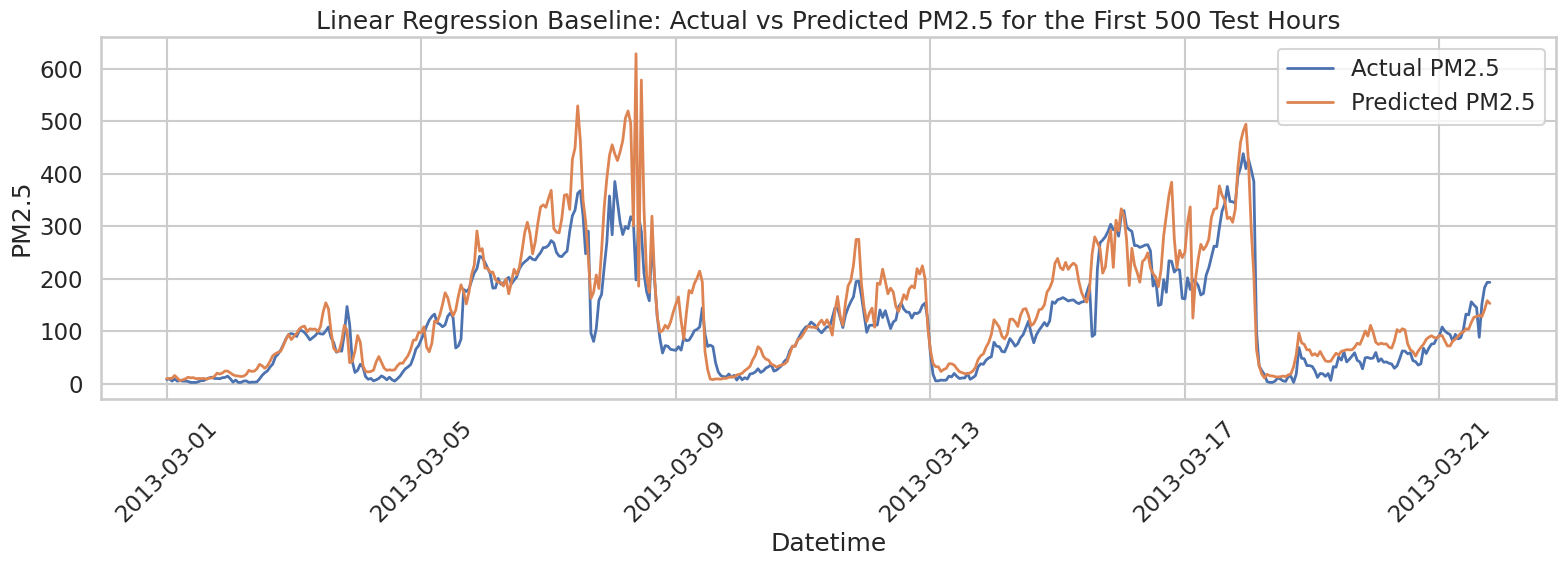

In [16]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

split_idx = int(len(X_scaled) * 0.8)

X_train = X_scaled.iloc[:split_idx].copy()
X_test = X_scaled.iloc[split_idx:].copy()
y_train = y.iloc[:split_idx].copy()
y_test = y.iloc[split_idx:].copy()
time_test = time_index.iloc[split_idx:].copy()


linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

y_pred_log = linear_model.predict(X_test)
y_test_original = np.expm1(y_test)
y_pred_original = np.expm1(y_pred_log)

metrics_df = pd.DataFrame(
    {
        "metric": ["MAE", "RMSE", "R2"],
        "value": [
            mean_absolute_error(y_test_original, y_pred_original),
            np.sqrt(mean_squared_error(y_test_original, y_pred_original)),
            r2_score(y_test_original, y_pred_original),
        ],
    }
)

display(metrics_df)

coef_df = (
    pd.DataFrame({"feature": X_train.columns, "coefficient": linear_model.coef_})
    .sort_values("coefficient", ascending=False)
    .reset_index(drop=True)
)

top_positive_coef = coef_df[coef_df["coefficient"] > 0].head(10)
top_negative_coef = coef_df[coef_df["coefficient"] < 0].sort_values("coefficient").head(10)

print("Top 10 positive coefficients")
display(top_positive_coef)

print("Top 10 negative coefficients")
display(top_negative_coef)

print("Because the features are Z-score standardized, larger absolute coefficients indicate a stronger association with log-transformed PM2.5, while the sign shows the direction of the relationship after controlling for the other variables.")

coef_lookup = coef_df.set_index("feature")["coefficient"]
wspm_coef = coef_lookup.get("WSPM")
rh_coef = coef_lookup.get("RH")
temp_coef = coef_lookup.get("TEMP")

if wspm_coef is not None:
    wspm_direction = "negative" if wspm_coef < 0 else "positive"
    wspm_effect = "lower" if wspm_coef < 0 else "higher"
    print(f"WSPM has a {wspm_direction} coefficient ({wspm_coef:.4f}), suggesting that stronger wind speed is associated with {wspm_effect} predicted PM2.5, holding the other features constant.")

if rh_coef is not None:
    rh_direction = "negative" if rh_coef < 0 else "positive"
    print(f"RH has a {rh_direction} coefficient ({rh_coef:.4f}), which indicates how humidity covaries with PM2.5 after controlling for the other variables.")

if temp_coef is not None:
    temp_direction = "negative" if temp_coef < 0 else "positive"
    temp_effect = "lower" if temp_coef < 0 else "higher"
    print(f"TEMP has a {temp_direction} coefficient ({temp_coef:.4f}), meaning higher temperature is associated with {temp_effect} predicted PM2.5 after accounting for the remaining predictors.")

test_results = pd.DataFrame(
    {
        "datetime": time_test.values,
        "actual_PM2.5": y_test_original.values,
        "predicted_PM2.5": y_pred_original,
    }
)

plot_df = (
    test_results.groupby("datetime", as_index=False)[["actual_PM2.5", "predicted_PM2.5"]]
    .mean()
    .head(500)
)

plt.figure(figsize=(16, 6))
sns.lineplot(data=plot_df, x="datetime", y="actual_PM2.5", label="Actual PM2.5", linewidth=2)
sns.lineplot(data=plot_df, x="datetime", y="predicted_PM2.5", label="Predicted PM2.5", linewidth=2)
plt.title("Linear Regression Baseline: Actual vs Predicted PM2.5 for the First 500 Test Hours")
plt.xlabel("Datetime")
plt.ylabel("PM2.5")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


The Linear Regression baseline achieved $R^2$ of 0.69. Pollutants like CO and Humidity (RH) are correctly identified as major drivers. However, the model shows a counter-intuitive positive coefficient for Wind Speed (WSPM), likely due to multicollinearity between weather variables.

In the actual vs. predicted plot (e.g., around March 9th and 17th), the model fails to reach the true heights of the $PM_{2.5}$ spikes. Linear regression suffers from "regression to the mean," making it too "timid" to predict the extreme concentrations that characterize heavy pollution events.



## LightGBM

In [17]:


try:
    import lightgbm as lgb
except ModuleNotFoundError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "lightgbm", "-q"])
    import lightgbm as lgb

from lightgbm import LGBMRegressor

In [18]:
station_cols = [col for col in preprocessed_df.columns if col.startswith("station_")]
if len(station_cols) != 12:
    raise ValueError(f"Expected 12 one-hot station columns, found {len(station_cols)}")

lgbm_df = preprocessed_df.copy()
lgbm_df["station"] = (
    lgbm_df[station_cols]
    .idxmax(axis=1)
    .str.replace("station_", "", regex=False)
)
lgbm_df["station"] = lgbm_df["station"].astype("category")
lgbm_df = lgbm_df.drop(columns=station_cols)
lgbm_df = lgbm_df.sort_values(["time_index", "station"]).reset_index(drop=True)

numerical_features = [
    "SO2", "NO2", "CO", "O3",
    "TEMP", "PRES", "DEWP", "RH", "RAIN", "WSPM",
    "lon", "lat", "elevation",
    "hour_sin", "hour_cos", "month_sin", "month_cos", "wd_sin", "wd_cos",
]
feature_cols = ["station"] + numerical_features

print("Total LightGBM features:", len(feature_cols))
display(pd.DataFrame({"feature": feature_cols, "dtype": [str(lgbm_df[col].dtype) for col in feature_cols]}))

split_idx_lgbm = int(len(lgbm_df) * 0.8)

X_lgbm = lgbm_df[feature_cols].copy()
y_lgbm = lgbm_df["PM2.5"].copy()
time_lgbm = lgbm_df["time_index"].copy()

X_train_lgbm = X_lgbm.iloc[:split_idx_lgbm].copy()
X_test_lgbm = X_lgbm.iloc[split_idx_lgbm:].copy()
y_train_lgbm = y_lgbm.iloc[:split_idx_lgbm].copy()
y_test_lgbm = y_lgbm.iloc[split_idx_lgbm:].copy()
time_test_lgbm = time_lgbm.iloc[split_idx_lgbm:].copy()

lgbm_model = LGBMRegressor(
    objective="regression",
    learning_rate=0.05,
    n_estimators=1000,
    num_leaves=31,
    random_state=42,
)

lgbm_model.fit(
    X_train_lgbm,
    y_train_lgbm,
    eval_set=[(X_test_lgbm, y_test_lgbm)],
    eval_metric="l2",
    categorical_feature=["station"],
    callbacks=[lgb.early_stopping(50, verbose=False)],
)

y_pred_lgbm_log = lgbm_model.predict(X_test_lgbm)
y_test_lgbm_original = np.expm1(y_test_lgbm)
y_pred_lgbm_original = np.expm1(y_pred_lgbm_log)


Total LightGBM features: 20


,feature,dtype
0,station,category
1,SO2,float64
2,NO2,float64
3,CO,float64
4,O3,float64
5,TEMP,float64
6,PRES,float64
7,DEWP,float64
8,RH,float64
9,RAIN,float64


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.006242 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2299
[LightGBM] [Info] Number of data points in the train set: 329623, number of used features: 20
[LightGBM] [Info] Start training from score 3.891521


,metric,value
0,MAE,22.31
1,RMSE,39.68
2,R2,0.77


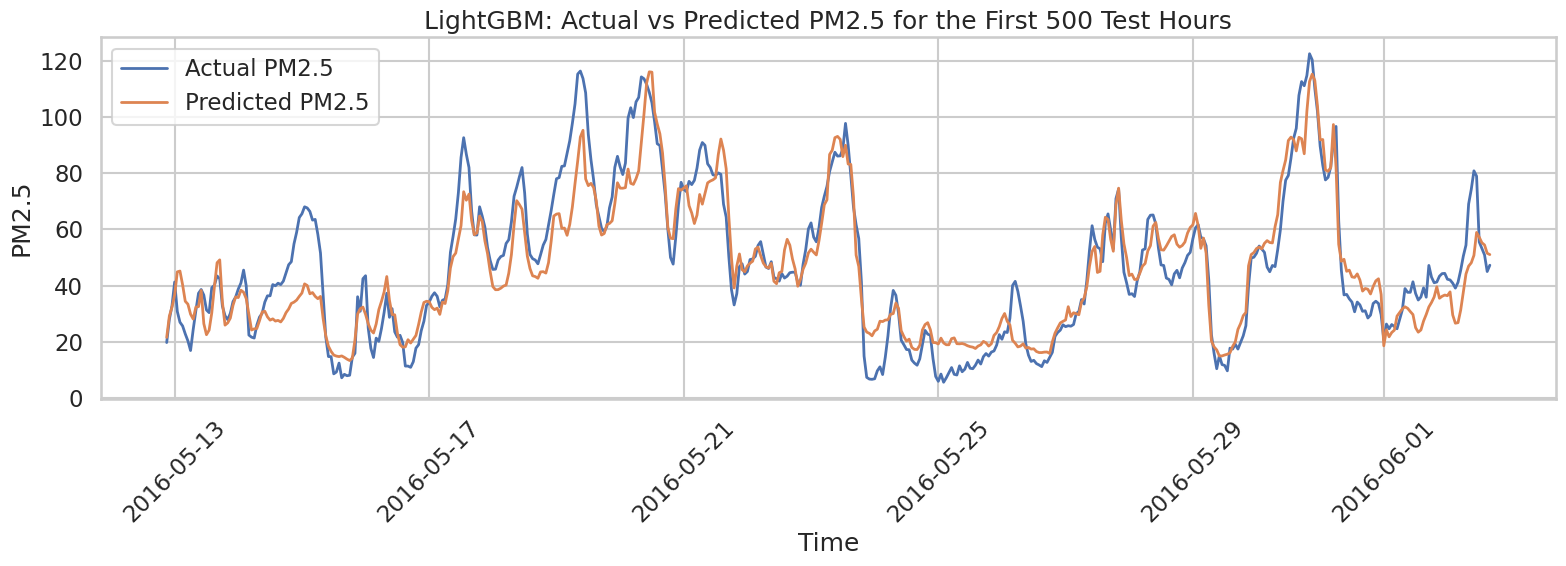

In [19]:

lgbm_metrics_df = pd.DataFrame(
    {
        "metric": ["MAE", "RMSE", "R2"],
        "value": [
            mean_absolute_error(y_test_lgbm_original, y_pred_lgbm_original),
            np.sqrt(mean_squared_error(y_test_lgbm_original, y_pred_lgbm_original)),
            r2_score(y_test_lgbm_original, y_pred_lgbm_original),
        ],
    }
)


display(lgbm_metrics_df)

lgbm_plot_df = (
    pd.DataFrame(
        {
            "time_index": time_test_lgbm.values,
            "actual_PM2.5": y_test_lgbm_original.values,
            "predicted_PM2.5": y_pred_lgbm_original,
        }
    )
    .groupby("time_index", as_index=False)[["actual_PM2.5", "predicted_PM2.5"]]
    .mean()
    .head(500)
)

plt.figure(figsize=(16, 6))
sns.lineplot(data=lgbm_plot_df, x="time_index", y="actual_PM2.5", label="Actual PM2.5", linewidth=2)
sns.lineplot(data=lgbm_plot_df, x="time_index", y="predicted_PM2.5", label="Predicted PM2.5", linewidth=2)
plt.title("LightGBM: Actual vs Predicted PM2.5 for the First 500 Test Hours")
plt.xlabel("Time")
plt.ylabel("PM2.5")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


,feature,gain_importance,split_importance,gain_pct
0,CO,"2,592,254.47",1845,73.52
1,DEWP,"225,745.88",2369,6.40
2,NO2,"138,806.81",1533,3.94
3,SO2,"116,807.53",1575,3.31
4,month_sin,"76,810.63",1387,2.18
5,O3,"62,096.52",1570,1.76
6,RH,"55,834.10",1529,1.58
7,PRES,"54,913.83",1957,1.56
8,station,"44,753.83",1890,1.27
9,month_cos,"43,872.20",885,1.24


,feature,gain_importance,split_importance,gain_pct
0,CO,"2,592,254.47",1845,73.52
1,DEWP,"225,745.88",2369,6.40
2,NO2,"138,806.81",1533,3.94
3,SO2,"116,807.53",1575,3.31
4,month_sin,"76,810.63",1387,2.18
5,O3,"62,096.52",1570,1.76
6,RH,"55,834.10",1529,1.58
7,PRES,"54,913.83",1957,1.56
8,station,"44,753.83",1890,1.27
9,month_cos,"43,872.20",885,1.24


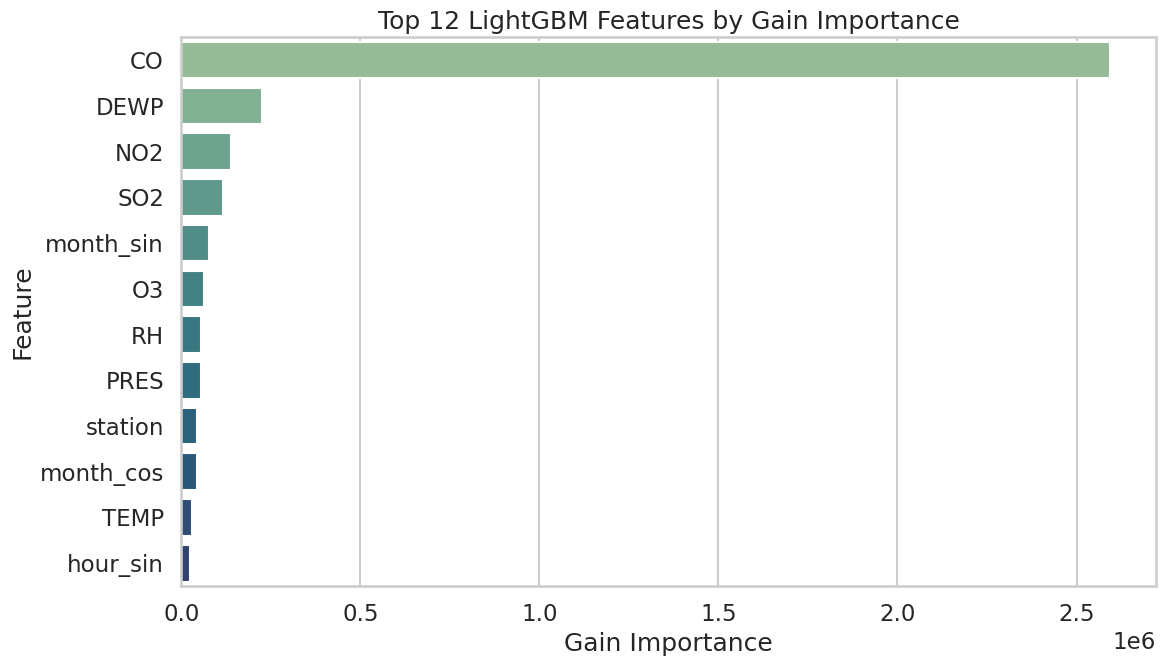

Top 5 features by gain importance:


,feature,gain_pct
0,CO,73.52
1,DEWP,6.40
2,NO2,3.94
3,SO2,3.31
4,month_sin,2.18


CO: rank 1, gain share 73.52%
NO2: rank 3, gain share 3.94%
RH: rank 7, gain share 1.58%
WSPM: rank 14, gain share 0.24%
station: rank 9, gain share 1.27%
TEMP: rank 11, gain share 0.82%


In [20]:
## LightGBM Feature Importance

gain_importance = pd.DataFrame(
    {
        "feature": lgbm_model.booster_.feature_name(),
        "gain_importance": lgbm_model.booster_.feature_importance(importance_type="gain"),
        "split_importance": lgbm_model.booster_.feature_importance(importance_type="split"),
    }
).sort_values("gain_importance", ascending=False).reset_index(drop=True)

gain_importance["gain_pct"] = 100 * gain_importance["gain_importance"] / gain_importance["gain_importance"].sum()

display(gain_importance)
display(gain_importance.head(10))

plt.figure(figsize=(12, 7))
sns.barplot(
    data=gain_importance.head(12),
    x="gain_importance",
    y="feature",
    hue="feature",
    dodge=False,
    legend=False,
    palette="crest",
)
plt.title("Top 12 LightGBM Features by Gain Importance")
plt.xlabel("Gain Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

top_features = gain_importance.head(5)[["feature", "gain_pct"]]
print("Top 5 features by gain importance:")
display(top_features)

important_set = set(gain_importance.head(10)["feature"])
for feature_name in ["CO", "NO2", "RH", "WSPM", "station", "TEMP"]:
    if feature_name in gain_importance["feature"].values:
        row = gain_importance.loc[gain_importance["feature"] == feature_name].iloc[0]
        print(f"{feature_name}: rank {gain_importance.index[gain_importance['feature'] == feature_name][0] + 1}, gain share {row['gain_pct']:.2f}%")


## LightGBM for Spatial generalization on unseen station





In [22]:
spatial_generalization_holdout_station = "Dingling"

spatial_generalization_df = df.copy()
spatial_generalization_df["time_index"] = pd.to_datetime(
    spatial_generalization_df[["year", "month", "day", "hour"]]
)
spatial_generalization_df = spatial_generalization_df.dropna(subset=["PM2.5"]).copy()
spatial_generalization_df = spatial_generalization_df.sort_values(
    ["station", "time_index"]
).reset_index(drop=True)

spatial_generalization_pollutant_cols = ["CO", "O3", "NO2", "SO2"]
spatial_generalization_meteorological_cols = ["TEMP", "PRES", "DEWP", "RAIN", "WSPM"]

for col in spatial_generalization_pollutant_cols:
    station_median = spatial_generalization_df.groupby("station")[col].transform("median")
    spatial_generalization_df[col] = spatial_generalization_df[col].fillna(station_median)
    spatial_generalization_df[col] = spatial_generalization_df[col].fillna(
        spatial_generalization_df[col].median()
    )

for col in spatial_generalization_meteorological_cols:
    spatial_generalization_df[col] = spatial_generalization_df.groupby("station")[col].transform(
        lambda s: s.interpolate(method="linear", limit_direction="both")
    )

es = 6.112 * np.exp(
    (17.67 * spatial_generalization_df["TEMP"])
    / (spatial_generalization_df["TEMP"] + 243.5)
)
e = 6.112 * np.exp(
    (17.67 * spatial_generalization_df["DEWP"])
    / (spatial_generalization_df["DEWP"] + 243.5)
)
spatial_generalization_df["RH"] = (100 * e / es).clip(0, 100)

spatial_generalization_df["hour_sin"] = np.sin(
    2 * np.pi * spatial_generalization_df["hour"] / 24
)
spatial_generalization_df["hour_cos"] = np.cos(
    2 * np.pi * spatial_generalization_df["hour"] / 24
)
spatial_generalization_df["month_sin"] = np.sin(
    2 * np.pi * spatial_generalization_df["month"] / 12
)
spatial_generalization_df["month_cos"] = np.cos(
    2 * np.pi * spatial_generalization_df["month"] / 12
)
spatial_generalization_df["y_log_pm25"] = np.log1p(spatial_generalization_df["PM2.5"])

spatial_generalization_feature_cols = [
    "TEMP", "RH", "WSPM", "RAIN", "PRES",
    "CO", "NO2", "SO2", "O3",
    "lon", "lat", "elevation",
    "hour_sin", "hour_cos", "month_sin", "month_cos",
]

train_spatial_generalization_df = spatial_generalization_df[
    spatial_generalization_df["station"] != spatial_generalization_holdout_station
].copy()
test_spatial_generalization_df = spatial_generalization_df[
    spatial_generalization_df["station"] == spatial_generalization_holdout_station
].copy()

X_train_spatial_generalization = train_spatial_generalization_df[
    spatial_generalization_feature_cols
].copy()
X_test_spatial_generalization = test_spatial_generalization_df[
    spatial_generalization_feature_cols
].copy()
y_train_spatial_generalization = train_spatial_generalization_df["y_log_pm25"].copy()
y_test_spatial_generalization = test_spatial_generalization_df["y_log_pm25"].copy()


In [23]:
spatial_generalization_model = LGBMRegressor(
    objective="regression",
    learning_rate=0.05,
    n_estimators=1000,
    num_leaves=31,
    random_state=42,
)

spatial_generalization_model.fit(
    X_train_spatial_generalization,
    y_train_spatial_generalization,
    eval_set=[(X_test_spatial_generalization, y_test_spatial_generalization)],
    eval_metric="l2",
    callbacks=[lgb.early_stopping(50, verbose=False)],
)

y_pred_spatial_generalization_log = spatial_generalization_model.predict(
    X_test_spatial_generalization
)
y_test_spatial_generalization_original = np.expm1(y_test_spatial_generalization)
y_pred_spatial_generalization_original = np.expm1(y_pred_spatial_generalization_log)

spatial_generalization_metrics_df = pd.DataFrame(
    {
        "metric": ["MAE", "RMSE", "R2"],
        "value": [
            mean_absolute_error(
                y_test_spatial_generalization_original,
                y_pred_spatial_generalization_original,
            ),
            np.sqrt(
                mean_squared_error(
                    y_test_spatial_generalization_original,
                    y_pred_spatial_generalization_original,
                )
            ),
            r2_score(
                y_test_spatial_generalization_original,
                y_pred_spatial_generalization_original,
            ),
        ],
    }
)

display(spatial_generalization_metrics_df)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.007020 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2006
[LightGBM] [Info] Number of data points in the train set: 377744, number of used features: 16
[LightGBM] [Info] Start training from score 3.906732


,metric,value
0,MAE,20.82
1,RMSE,36.00
2,R2,0.75


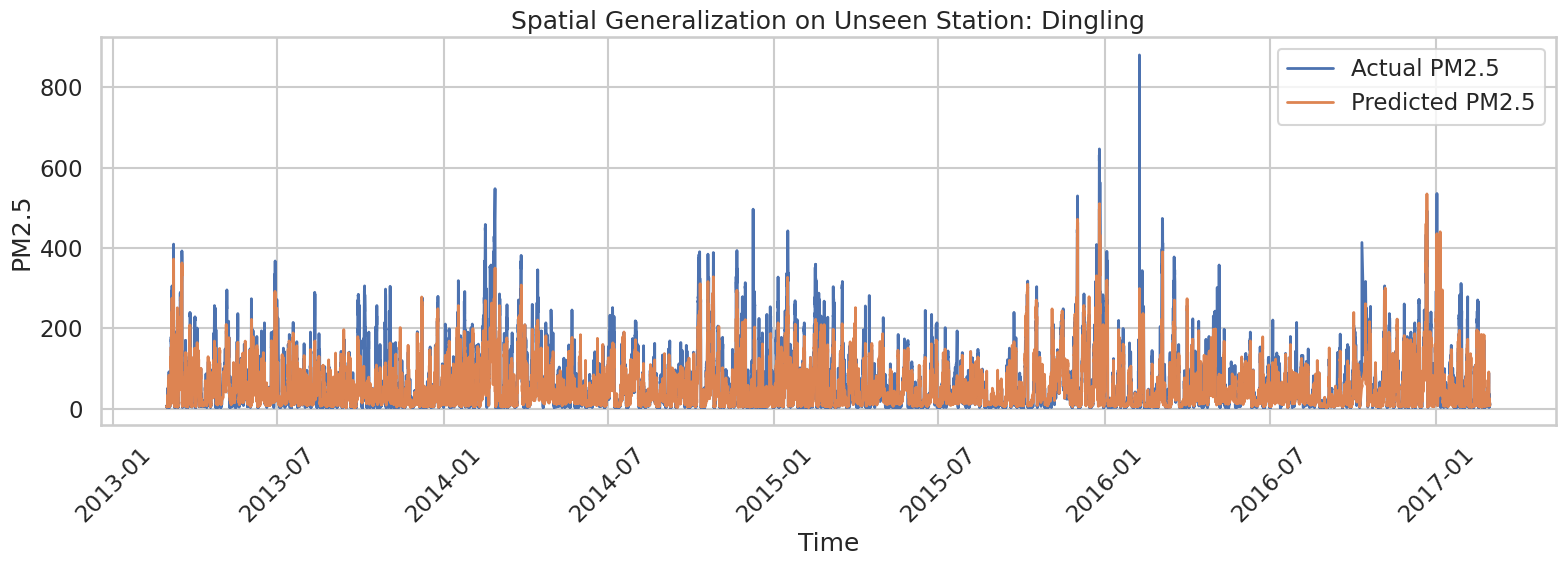

In [24]:
spatial_generalization_plot_df = pd.DataFrame(
    {
        "time_index": test_spatial_generalization_df["time_index"].values,
        "actual_PM2.5": y_test_spatial_generalization_original.values,
        "predicted_PM2.5": y_pred_spatial_generalization_original,
    }
).sort_values("time_index")

plt.figure(figsize=(16, 6))
sns.lineplot(
    data=spatial_generalization_plot_df,
    x="time_index",
    y="actual_PM2.5",
    label="Actual PM2.5",
    linewidth=2,
)
sns.lineplot(
    data=spatial_generalization_plot_df,
    x="time_index",
    y="predicted_PM2.5",
    label="Predicted PM2.5",
    linewidth=2,
)
plt.title(
    f"Spatial Generalization on Unseen Station: {spatial_generalization_holdout_station}"
)
plt.xlabel("Time")
plt.ylabel("PM2.5")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### Leave-One-Station-Out Spatial Validation


In [25]:
loso_spatial_results = []

loso_spatial_stations = sorted(spatial_generalization_df["station"].unique())

for holdout_station in loso_spatial_stations:
    train_loso_df = spatial_generalization_df[
        spatial_generalization_df["station"] != holdout_station
    ].copy()
    test_loso_df = spatial_generalization_df[
        spatial_generalization_df["station"] == holdout_station
    ].copy()

    X_train_loso = train_loso_df[spatial_generalization_feature_cols].copy()
    X_test_loso = test_loso_df[spatial_generalization_feature_cols].copy()
    y_train_loso = train_loso_df["y_log_pm25"].copy()
    y_test_loso = test_loso_df["y_log_pm25"].copy()

    loso_model = LGBMRegressor(
        objective="regression",
        learning_rate=0.05,
        n_estimators=1000,
        num_leaves=31,
        random_state=42,
    )

    loso_model.fit(
        X_train_loso,
        y_train_loso,
        eval_set=[(X_test_loso, y_test_loso)],
        eval_metric="l2",
        callbacks=[lgb.early_stopping(50, verbose=False)],
    )

    y_pred_loso_log = loso_model.predict(X_test_loso)
    y_test_loso_original = np.expm1(y_test_loso)
    y_pred_loso_original = np.expm1(y_pred_loso_log)

    loso_spatial_results.append(
        {
            "holdout_station": holdout_station,
            "train_rows": len(train_loso_df),
            "test_rows": len(test_loso_df),
            "MAE": mean_absolute_error(y_test_loso_original, y_pred_loso_original),
            "RMSE": np.sqrt(mean_squared_error(y_test_loso_original, y_pred_loso_original)),
            "R2": r2_score(y_test_loso_original, y_pred_loso_original),
        }
    )

loso_spatial_results_df = pd.DataFrame(loso_spatial_results).sort_values("R2", ascending=False)
display(loso_spatial_results_df)

loso_spatial_summary_df = (
    loso_spatial_results_df[["MAE", "RMSE", "R2"]]
    .agg(["mean", "std", "min", "max"])
    .reset_index()
    .rename(columns={"index": "summary_stat"})
)
display(loso_spatial_summary_df)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.023007 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2013
[LightGBM] [Info] Number of data points in the train set: 377890, number of used features: 16
[LightGBM] [Info] Start training from score 3.877979
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.005848 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2004
[LightGBM] [Info] Number of data points in the train set: 377739, number of used features: 16
[LightGBM] [Info] Start training from score 3.892966
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.005660 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total 

,holdout_station,train_rows,test_rows,MAE,RMSE,R2
7,Nongzhanguan,377593,34436,19.36,31.58,0.87
4,Guanyuan,377581,34448,19.10,30.57,0.86
11,Wanshouxigong,377661,34368,21.34,35.32,0.83
10,Wanliu,377347,34682,21.18,34.14,0.83
3,Dongsi,377715,34314,21.56,36.21,0.83
0,Aotizhongxin,377890,34139,20.97,34.37,0.82
9,Tiantan,377642,34387,21.02,35.62,0.81
5,Gucheng,377611,34418,21.67,36.46,0.81
6,Huairou,377918,34111,19.58,31.59,0.80
1,Changping,377739,34290,19.51,32.12,0.80


,summary_stat,MAE,RMSE,R2
0,mean,20.75,34.43,0.81
1,std,1.14,2.54,0.03
2,min,19.10,30.57,0.75
3,max,22.87,39.16,0.87


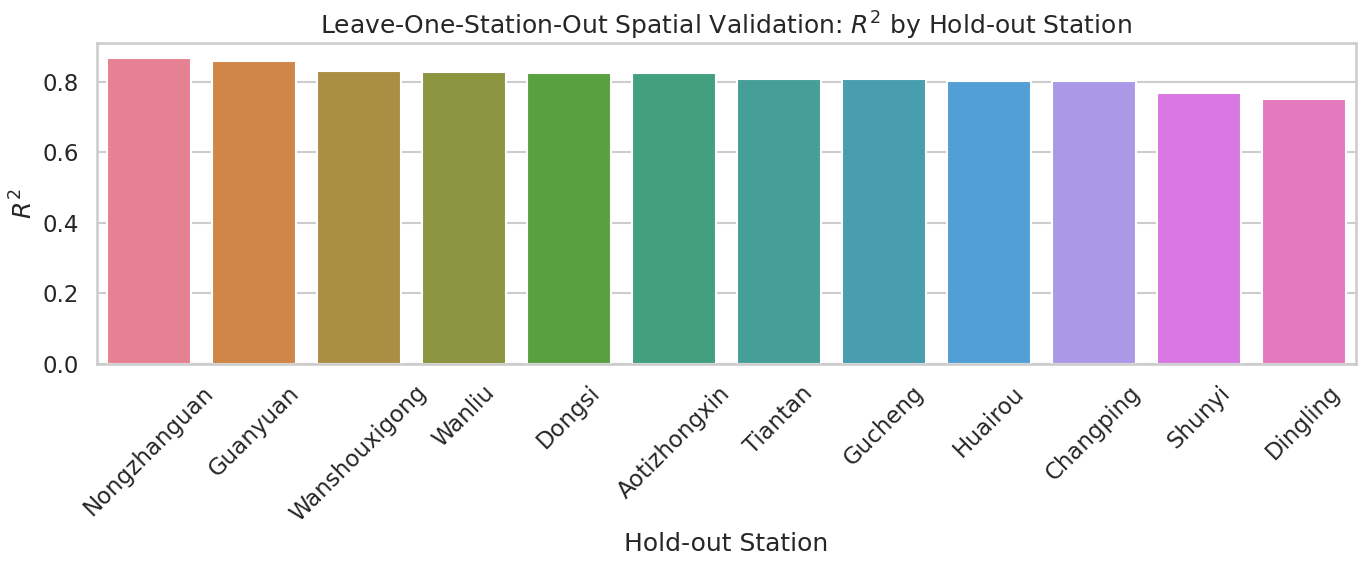

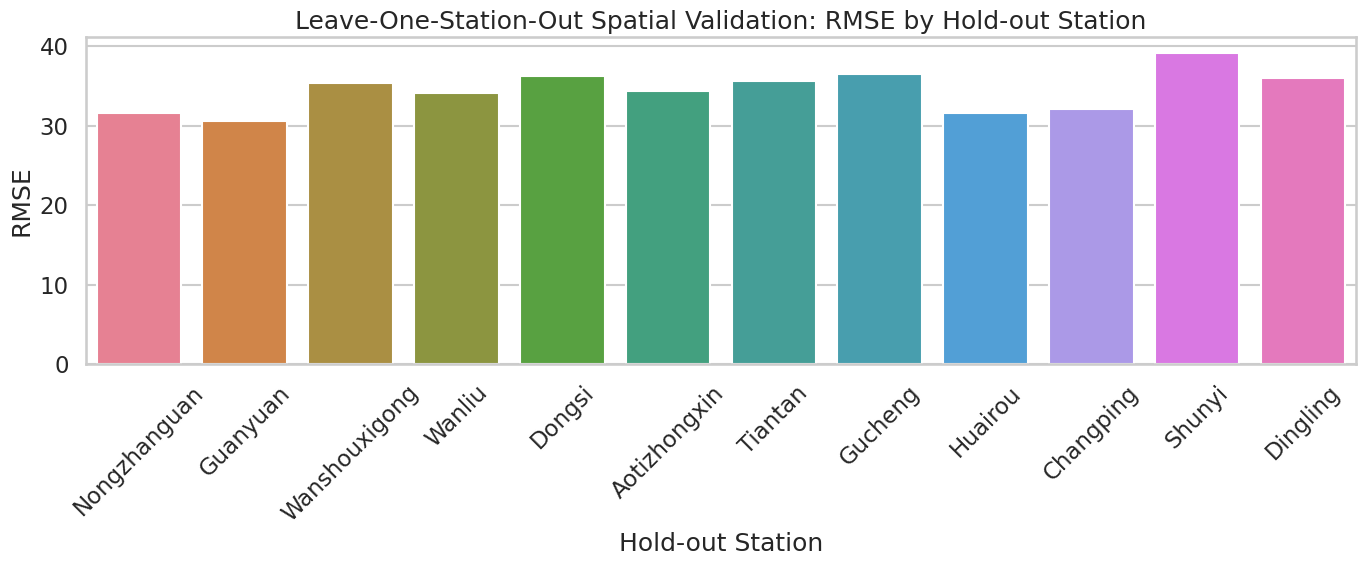

In [26]:
plt.figure(figsize=(14, 6))
loso_spatial_plot_df = loso_spatial_results_df.sort_values("R2", ascending=False)
sns.barplot(
    data=loso_spatial_plot_df,
    x="holdout_station",
    y="R2",
    hue="holdout_station",
    dodge=False,
    legend=False,
)
plt.title("Leave-One-Station-Out Spatial Validation: $R^2$ by Hold-out Station")
plt.xlabel("Hold-out Station")
plt.ylabel("$R^2$")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 6))
sns.barplot(
    data=loso_spatial_plot_df,
    x="holdout_station",
    y="RMSE",
    hue="holdout_station",
    dodge=False,
    legend=False,
)
plt.title("Leave-One-Station-Out Spatial Validation: RMSE by Hold-out Station")
plt.xlabel("Hold-out Station")
plt.ylabel("RMSE")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()